# 01 · Data quality, cleaning and sampling

**EDA Steps 1–2.** This notebook goes through the 8 raw months one at a time, so no more than one month is in memory at once. For each month it:

1. Records data-quality checks on the **raw** file (missing values, payment mix, value ranges)
2. Cleans the month (card-paid trips only, rules in `taxi_utils.RULES`) and logs how many rows each rule removes
3. Adds features and saves **full-data summary tables** (used for headline numbers in notebooks 02–03)
4. Takes a random sample of 250K trips and saves it to `data/sample/`

Run this notebook first. It takes a few minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import taxi_utils as tu

tu.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
zones = tu.load_zones()
tu.RULES

FileNotFoundError: [Errno 2] No such file or directory: '/Users/macbookpro/Downloads/DATA 400 - Final Project/taxi-tips/data/raw/taxi_zone_lookup.csv'

## Loop over the 8 months

In [2]:
PAYMENT_LABELS = {1: "Card", 2: "Cash", 0: "Type 0", 3: "Other", 4: "Other", 5: "Other", 6: "Other"}
SANITY_COLS = ["fare_amount", "trip_distance", "tip_amount", "tolls_amount",
               "total_amount", "congestion_surcharge", "airport_fee"]

funnels, missing, payments, sanity = {}, {}, {}, []
month_summary, by_zone, by_hour, by_day, by_borough, by_cbd = [], [], [], [], [], []

for m in tu.MONTHS:
    raw = tu.load_month(m)

    # --- Step 1: raw data quality ---
    missing[m] = raw.isna().mean() * 100
    payments[m] = raw.payment_type.map(PAYMENT_LABELS).fillna("Other").value_counts(normalize=True) * 100
    q = raw[SANITY_COLS].quantile([0, 0.01, 0.5, 0.99, 1]).T
    q.columns = ["min", "p1", "median", "p99", "max"]
    sanity.append(q.assign(month=m))

    # --- clean + features ---
    clean, funnel = tu.clean_month(raw, m)
    del raw
    funnels[m] = dict(funnel)
    df = tu.add_features(clean, zones)
    del clean

    # --- full-data summaries ---
    s = tu.summarize(df, ["year", "month_name"]).iloc[0].to_dict()
    s.update(month=m, mean_fare=df.fare_amount.mean(), mean_distance=df.trip_distance.mean(),
             mean_duration=df.duration_min.mean(), airport_share=df.is_airport.mean() * 100)
    month_summary.append(s)
    by_zone.append(tu.summarize(df, ["year", "month_name", "PULocationID", "pu_zone", "pu_borough"]))
    by_hour.append(tu.summarize(df, ["year", "month_name", "hour"]))
    by_borough.append(tu.summarize(df, ["year", "month_name", "pu_borough"]))
    by_day.append(df.groupby(["year", "month_name", "day"]).size().rename("trips").reset_index())
    if df.year.iloc[0] == tu.TEST_YEAR:
        by_cbd.append(tu.summarize(df, ["year", "month_name", "paid_cbd_fee"]))

    # --- Step 2: sample ---
    sample = df.sample(n=tu.N_PER_MONTH, random_state=tu.SEED)
    sample.to_parquet(tu.SAMPLE / f"sample_{m}.parquet", index=False)
    print(f"{m}: {funnel[0][1]:>10,} raw -> {len(df):>10,} clean -> {len(sample):,} sampled")
    del df, sample

2022-02:  2,979,431 raw ->  2,240,280 clean -> 250,000 sampled


2022-12:  3,399,549 raw ->  2,464,551 clean -> 250,000 sampled


2023-02:  2,913,955 raw ->  2,245,271 clean -> 250,000 sampled


2023-12:  3,376,567 raw ->  2,516,672 clean -> 250,000 sampled


2024-02:  3,007,526 raw ->  2,295,031 clean -> 250,000 sampled


2024-12:  3,668,371 raw ->  2,673,968 clean -> 250,000 sampled


2025-02:  3,577,543 raw ->  2,288,321 clean -> 250,000 sampled


2025-12:  4,305,006 raw ->  2,513,898 clean -> 250,000 sampled


## Step 1a · Cleaning funnel

Rows left after each rule is applied (in order). The last row is the cleaned data set. Save this as part of the cleaning log.

In [3]:
funnel_tbl = pd.DataFrame(funnels)
funnel_tbl.to_csv(tu.DOCS / "cleaning_funnel.csv")
funnel_tbl.style.format("{:,.0f}")

,2022-02,2022-12,2023-02,2023-12,2024-02,2024-12,2025-02,2025-12
raw rows,"2,979,431","3,399,549","2,913,955","3,376,567","3,007,526","3,668,371","3,577,543","4,305,006"
pickup inside the month,"2,979,367","3,399,503","2,913,900","3,376,524","3,007,511","3,668,337","3,577,512","4,304,997"
card-paid (payment_type = 1),"2,296,167","2,553,771","2,309,545","2,574,541","2,341,998","2,733,337","2,336,147","2,618,764"
fare >= $2.50,"2,295,679","2,553,338","2,309,259","2,574,276","2,341,813","2,733,204","2,336,037","2,618,420"
tip >= 0,"2,295,679","2,553,338","2,309,259","2,574,276","2,341,813","2,733,204","2,336,037","2,618,420"
0 < distance <= 100 mi,"2,278,264","2,526,503","2,289,828","2,551,823","2,322,201","2,708,888","2,317,026","2,594,080"
1-180 min duration,"2,272,525","2,518,331","2,284,721","2,545,681","2,317,391","2,702,072","2,308,747","2,537,893"
speed <= 80 mph,"2,272,452","2,518,244","2,284,659","2,545,631","2,317,361","2,701,961","2,308,700","2,537,812"
known pickup & drop-off zone,"2,244,093","2,469,078","2,247,707","2,520,128","2,297,708","2,678,067","2,291,230","2,517,901"
tip % <= 100,"2,240,280","2,464,551","2,245,271","2,516,672","2,295,031","2,673,968","2,288,321","2,513,898"


In [4]:
# Same funnel as % of rows removed at each step
removed = (-funnel_tbl.diff()).iloc[1:] / funnel_tbl.iloc[0] * 100
removed.loc["total kept (% of raw)"] = funnel_tbl.iloc[-1] / funnel_tbl.iloc[0] * 100
removed.style.format("{:.2f}%")

,2022-02,2022-12,2023-02,2023-12,2024-02,2024-12,2025-02,2025-12
pickup inside the month,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%
card-paid (payment_type = 1),22.93%,24.88%,20.74%,23.75%,22.13%,25.49%,34.70%,39.17%
fare >= $2.50,0.02%,0.01%,0.01%,0.01%,0.01%,0.00%,0.00%,0.01%
tip >= 0,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%,-0.00%
0 < distance <= 100 mi,0.58%,0.79%,0.67%,0.66%,0.65%,0.66%,0.53%,0.57%
1-180 min duration,0.19%,0.24%,0.18%,0.18%,0.16%,0.19%,0.23%,1.31%
speed <= 80 mph,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%
known pickup & drop-off zone,0.95%,1.45%,1.27%,0.76%,0.65%,0.65%,0.49%,0.46%
tip % <= 100,0.13%,0.13%,0.08%,0.10%,0.09%,0.11%,0.08%,0.09%
total kept (% of raw),75.19%,72.50%,77.05%,74.53%,76.31%,72.89%,63.96%,58.39%


## Step 1b · Missing values (% of raw rows)

Only columns with at least one missing value are shown. `cbd_congestion_fee` is 100% missing before 2025 because the column did not exist.

In [5]:
miss_tbl = pd.DataFrame(missing)
miss_tbl = miss_tbl[miss_tbl.sum(axis=1) > 0]
miss_tbl.to_csv(tu.DOCS / "missing_values.csv")
miss_tbl.style.format("{:.2f}%")

,2022-02,2022-12,2023-02,2023-12,2024-02,2024-12,2025-02,2025-12
passenger_count,3.41%,3.72%,2.64%,5.33%,6.17%,8.89%,22.56%,27.77%
RatecodeID,3.41%,3.72%,2.64%,5.33%,6.17%,8.89%,22.56%,27.77%
congestion_surcharge,3.41%,3.72%,2.64%,5.33%,6.17%,8.89%,22.56%,27.77%
airport_fee,3.41%,3.72%,2.64%,5.33%,6.17%,8.89%,22.56%,27.77%
cbd_congestion_fee,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%


## Step 1c · Payment type mix 📊

Check the TLC data dictionary for what payment type 0 means. It grows a lot in 2025.

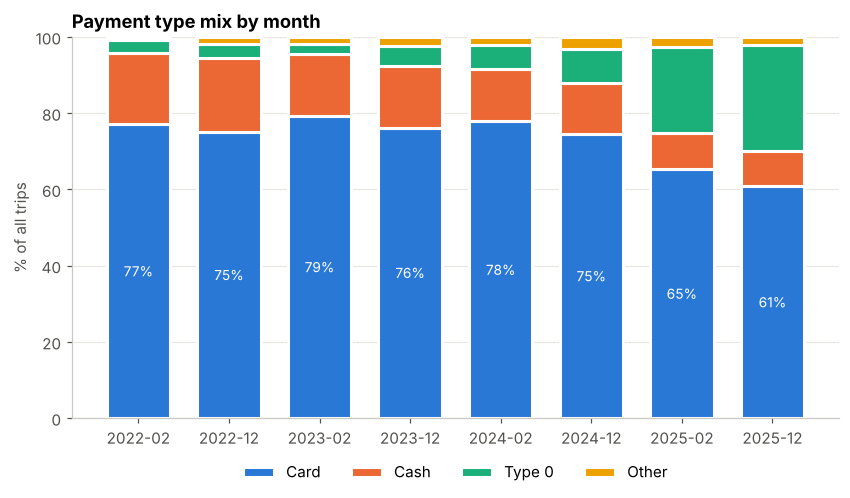

payment_type,Card,Cash,Type 0,Other
2022-02,77.10,18.70,3.40,0.90
2022-12,75.10,19.40,3.70,1.70
2023-02,79.30,16.40,2.60,1.70
2023-12,76.20,16.20,5.30,2.20
2024-02,77.90,13.70,6.20,2.20
2024-12,74.50,13.40,8.90,3.20
2025-02,65.30,9.50,22.60,2.70
2025-12,60.80,9.30,27.80,2.10


In [6]:
pay_tbl = pd.DataFrame(payments).T[["Card", "Cash", "Type 0", "Other"]].fillna(0)
pay_tbl.to_csv(tu.DOCS / "payment_mix.csv")

colors = {"Card": tu.FEB, "Cash": "#eb6834", "Type 0": "#1baf7a", "Other": "#eda100"}
fig, ax = plt.subplots(figsize=(9, 4.5))
bottom = np.zeros(len(pay_tbl))
for col in pay_tbl.columns:
    ax.bar(pay_tbl.index, pay_tbl[col], bottom=bottom, color=colors[col],
           edgecolor="white", linewidth=2, label=col, width=0.7)
    bottom += pay_tbl[col].values
for i, v in enumerate(pay_tbl["Card"]):
    ax.text(i, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
ax.set_ylabel("% of all trips")
ax.set_ylim(0, 100)
ax.set_title("Payment type mix by month")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
tu.save_fig(fig, "01_payment_mix")
plt.show()
pay_tbl.round(1)

## Step 1d · Value ranges on the raw data

Look for negative values and extreme maximums. These are what the cleaning rules target.

In [7]:
sanity_tbl = pd.concat(sanity).reset_index(names="column").set_index(["column", "month"]).sort_index()
sanity_tbl.to_csv(tu.DOCS / "sanity_ranges.csv")
sanity_tbl

min     p1  median    p99  \
column               month                                           
airport_fee          2022-02           -1.25   0.00    0.00   1.25   
                     2022-12           -1.25   0.00    0.00   1.25   
                     2023-02           -1.25   0.00    0.00   1.25   
                     2023-12           -1.75   0.00    0.00   1.75   
                     2024-02           -1.75   0.00    0.00   1.75   
                     2024-12           -1.75   0.00    0.00   1.75   
                     2025-02           -1.75   0.00    0.00   1.75   
                     2025-12           -1.75   0.00    0.00   1.75   
congestion_surcharge 2022-02           -2.50   0.00    2.50   2.50   
                     2022-12           -2.50   0.00    2.50   2.50   
                     2023-02           -2.50   0.00    2.50   2.50   
                     2023-12           -2.50  -2.50    2.50   2.50   
                     2024-02           -2.50  -2.50    2.50   2.50   
                     2024-12           -2.50  -2.50    2.50   2.50   
                     2025-02           -2.50  -2.50    2.50   2.50   
                     2025-12           -2.50  -2.50    2.50   2.50   
fare_amount          2022-02         -600.00   3.00    9.50  52.00   
                     2022-12 -133,391,414.00   2.50   12.00  70.00   
                     2023-02         -754.05   3.00   12.80  71.71   
                     2023-12       -1,087.30  -4.40   14.20  79.80   
                     2024-02         -999.00  -5.10   12.80  73.40   
                     2024-12         -975.00 -12.80   14.20  84.00   
                     2025-02       -1,807.60  -9.30   12.80  70.00   
                     2025-12       -1,377.10  -4.40   16.94  85.77   
tip_amount           2022-02         -188.00   0.00    2.06  12.67   
                     2022-12         -110.00   0.00    2.36  16.36   
                     2023-02          -93.00   0.00    2.80  17.11   
                     2023-12          -80.00   0.00    2.80  18.21   
                     2024-02         -140.00   0.00    2.70  17.19   
                     2024-12          -80.00   0.00    2.72  18.60   
                     2025-02         -220.00   0.00    2.11  16.69   
                     2025-12          -96.50   0.00    2.00  17.85   
tolls_amount         2022-02          -29.05   0.00    0.00   6.55   
                     2022-12          -49.50   0.00    0.00   6.55   
                     2023-02          -57.00   0.00    0.00   6.55   
                     2023-12          -70.00   0.00    0.00   6.94   
                     2024-02          -58.45   0.00    0.00   6.94   
                     2024-12          -70.38   0.00    0.00   6.94   
                     2025-02         -113.93   0.00    0.00   6.94   
                     2025-12         -106.93   0.00    0.00   6.94   
total_amount         2022-02         -600.30   5.80   15.30  75.72   
                     2022-12       -1,635.80   4.50   18.00  97.91   
                     2023-02         -757.55   5.20   20.20 101.94   
                     2023-12       -1,094.05  -9.40   21.40 104.88   
                     2024-02       -1,000.00  -9.80   20.16 103.13   
                     2024-12         -951.00 -17.50   21.66 106.31   
                     2025-02       -1,832.85 -14.35   20.19 100.14   
                     2025-12       -1,382.85  -9.45   24.42 107.42   
trip_distance        2022-02            0.00   0.00    1.79  19.45   
                     2022-12            0.00   0.00    1.84  20.35   
                     2023-02            0.00   0.00    1.79  19.90   
                     2023-12            0.00   0.00    1.70  20.03   
                     2024-02            0.00   0.00    1.69  19.67   
                     2024-12            0.00   0.00    1.68  19.91   
                     2025-02            0.00   0.00    1.70  19.07   
                     2025-12            0.00   0.00

## Save the full-data summary tables

These are small tables computed from **all** cleaned trips. Notebooks 02–03 use them for headline numbers.

In [8]:
month_tbl = pd.DataFrame(month_summary)
month_tbl.to_csv(tu.PROCESSED / "full_by_month.csv", index=False)
pd.concat(by_zone).to_csv(tu.PROCESSED / "full_by_zone.csv", index=False)
pd.concat(by_hour).to_csv(tu.PROCESSED / "full_by_hour.csv", index=False)
pd.concat(by_day).to_csv(tu.PROCESSED / "full_by_day.csv", index=False)
pd.concat(by_borough).to_csv(tu.PROCESSED / "full_by_borough.csv", index=False)
pd.concat(by_cbd).to_csv(tu.PROCESSED / "full_by_cbd_2025.csv", index=False)
month_tbl.set_index("month")[["n", "mean", "median", "zero_tip_pct", "tip20_pct",
                              "mean_fare", "mean_distance", "airport_share"]]

,n,mean,median,zero_tip_pct,tip20_pct,mean_fare,mean_distance,airport_share
month,,,,,,,,
2022-02,2240280,26.30,26.84,3.43,79.25,12.77,3.06,7.11
2022-12,2464551,25.66,26.17,3.79,78.47,16.31,3.51,10.35
2023-02,2245271,25.01,26.13,4.05,75.53,18.08,3.28,9.16
2023-12,2516672,24.96,25.93,4.58,76.61,19.48,3.29,9.79
2024-02,2295031,25.09,26.25,4.77,76.11,18.03,3.17,8.86
2024-12,2673968,24.70,25.70,5.69,75.82,19.81,3.27,9.88
2025-02,2288321,25.70,27.04,5.88,75.76,17.46,3.05,8.39
2025-12,2513898,24.58,26.18,9.04,73.79,20.26,3.41,9.73


## Step 2 · Check that the sample matches the full data

The sample should be within a few hundredths of the full data on each metric. If it is, the sample represents the full data.

In [9]:
sample = pd.concat([pd.read_parquet(tu.SAMPLE / f"sample_{m}.parquet") for m in tu.MONTHS],
                   ignore_index=True)
samp = tu.summarize(sample, ["year", "month_name"])
samp_extra = sample.groupby(["year", "month_name"]).agg(
    mean_fare=("fare_amount", "mean"), mean_distance=("trip_distance", "mean"),
    airport_share=("is_airport", lambda s: s.mean() * 100)).reset_index()
samp = samp.merge(samp_extra, on=["year", "month_name"])

metrics = ["mean", "zero_tip_pct", "tip20_pct", "mean_fare", "mean_distance", "airport_share"]
full = month_tbl.set_index(["year", "month_name"])[metrics]
smp = samp.set_index(["year", "month_name"])[metrics]
check = pd.concat({"full": full, "sample": smp, "difference": smp - full}, axis=1)
check.to_csv(tu.DOCS / "sample_check.csv")
check.round(3)

full                                                 \
                 mean zero_tip_pct tip20_pct mean_fare mean_distance   
year month_name                                                        
2022 Feb        26.30         3.43     79.25     12.77          3.06   
     Dec        25.66         3.79     78.47     16.31          3.51   
2023 Feb        25.01         4.05     75.53     18.08          3.28   
     Dec        24.95         4.58     76.61     19.48          3.29   
2024 Feb        25.09         4.77     76.11     18.03          3.17   
     Dec        24.70         5.69     75.82     19.81          3.27   
2025 Feb        25.70         5.88     75.76     17.46          3.05   
     Dec        24.58         9.04     73.79     20.26          3.41   

                              sample                                   \
                airport_share   mean zero_tip_pct tip20_pct mean_fare   
year month_name                                                         
2022 Feb                 7.11  26.28         3.44     79.23     12.78   
     Dec                10.35  25.64         3.82     78.42     16.32   
2023 Feb                 9.16  25.01         4.10     75.46     18.04   
     Dec                 9.79  24.95         4.63     76.52     19.52   
2024 Feb                 8.86  25.11         4.80     76.19     18.03   
     Dec                 9.88  24.73         5.66     75.86     19.84   
2025 Feb                 8.39  25.68         5.89     75.71     17.44   
     Dec                 9.73  24.58         9.05     73.82     20.27   

                                            difference                         \
                mean_distance airport_share       mean zero_tip_pct tip20_pct   
year month_name                                                                 
2022 Feb                 3.06          7.07      -0.02         0.01     -0.02   
     Dec                 3.51         10.38      -0.02         0.03     -0.05   
2023 Feb                 3.26          9.15       0.00         0.05     -0.07   
     Dec                 3.30          9.86      -0.01         0.05     -0.09   
2024 Feb                 3.17          8.85       0.02         0.02      0.09   
     Dec                 3.28          9.92       0.03        -0.03      0.05   
2025 Feb                 3.05          8.38      -0.03         0.01     -0.05   
     Dec                 3.41          9.71      -0.00         0.02      0.03   

                                                       
                mean_fare mean_distance airport_share  
year month_name                                        
2022 Feb             0.01          0.00         -0.03  
     Dec             0.01          0.00          0.03  
2023 Feb            -0.04         -0.01         -0.01  
     Dec             0.04          0.01          0.07  
2024 Feb            -0.00          0.00         -0.01  
     Dec             0.03          0.01          0.04  
2025 Feb            -0.02         -0.01         -0.01  
     Dec             0.00          0.00         -0.02

In [10]:
print(f"Sample: {len(sample):,} trips, {sample.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
sample.head()

Sample: 2,000,000 trips, 0.55 GB in memory


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,...,same_zone,dist_bucket,tip_pct_total,paid_cbd_fee,zero_tip,tip_20plus,pu_borough,pu_zone,pu_service_zone,do_borough
0,1,2022-02-17 21:59:01,2022-02-17 22:04:31,1.00,0.60,1.00,79,79,1,5.00,...,True,0-1,29.55,False,False,True,Manhattan,East Village,Yellow Zone,Manhattan
1,2,2022-02-16 04:44:23,2022-02-16 04:55:04,1.00,3.70,1.00,186,145,1,12.50,...,False,3-7,20.00,False,False,True,Manhattan,Penn Station/Madison Sq West,Yellow Zone,Queens
2,1,2022-02-24 08:31:33,2022-02-24 08:41:59,1.00,1.10,1.00,236,43,1,8.00,...,False,1-3,17.70,False,False,True,Manhattan,Upper East Side North,Yellow Zone,Manhattan
3,2,2022-02-10 14:21:18,2022-02-10 14:38:17,5.00,1.75,1.00,161,249,1,11.50,...,False,1-3,30.00,False,False,True,Manhattan,Midtown Center,Yellow Zone,Manhattan
4,1,2022-02-01 11:30:29,2022-02-01 11:35:37,2.00,0.40,1.00,237,237,1,5.00,...,True,0-1,19.88,False,False,True,Manhattan,Upper East Side South,Yellow Zone,Manhattan
